In [62]:
# =========================================================
# Imports — manipulation et visualisation
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# Imports — Machine Learning (scikit-learn)
# =========================================================
# Préparation des données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Régression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor          # bonus
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import clone
# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier         # bonus
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

# Sauvegarde des modèles (pour les réutiliser dans Streamlit)
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# =========================================================
# 🔗 Jeu de données (lu directement depuis Internet)
# =========================================================
URL_SPOTIFY = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
df = pd.read_csv(URL_SPOTIFY)

In [63]:

print('Dimensions initiales :', df.shape)
print("Colonnes :")
# On liste les types de chaque colonne pour identifier les colonnes catégorielles et numériques.
print(df.dtypes.to_frame('type'))
# On vérifie la présence de valeurs manquantes.
print(df.isna().sum().sort_values(ascending=False).to_frame('valeurs_manquantes'))
# On vérifie la présence de morceaux associés à plusieurs genres.
genres_par_morceau = df.groupby('track_id')['playlist_genre'].nunique()
# On affiche le nombre de morceaux uniques, le nombre de lignes dupliquées et le nombre de morceaux associés à plusieurs genres.
print('Morceaux uniques :', df['track_id'].nunique())
# On affiche le nombre de morceaux uniques, le nombre de lignes dupliquées et le nombre de morceaux associés à plusieurs genres.
print('Lignes dupliquées par track_id :', int(df['track_id'].duplicated().sum()))
print('Morceaux associés à plusieurs genres :', int((genres_par_morceau > 1).sum()))

Dimensions initiales : (32833, 23)
Colonnes :
                             type
track_id                      str
track_name                    str
track_artist                  str
track_popularity            int64
track_album_id                str
track_album_name              str
track_album_release_date      str
playlist_name                 str
playlist_id                   str
playlist_genre                str
playlist_subgenre             str
danceability              float64
energy                    float64
key                         int64
loudness                  float64
mode                        int64
speechiness               float64
acousticness              float64
instrumentalness          float64
liveness                  float64
valence                   float64
tempo                     float64
duration_ms                 int64
                          valeurs_manquantes
track_name                                 5
track_artist                               5
tra

In [64]:

df = df.drop_duplicates(subset='track_id', keep='first').copy()
df['duration_min'] = df['duration_ms'] / 60000
df['playlist_genre'] = df['playlist_genre'].astype('category')

cleaned_df = df.copy()  # <-- dataSet propre pour backup

print('Dimensions après déduplication :', df.shape)
# print(df.head())

Dimensions après déduplication : (28356, 24)


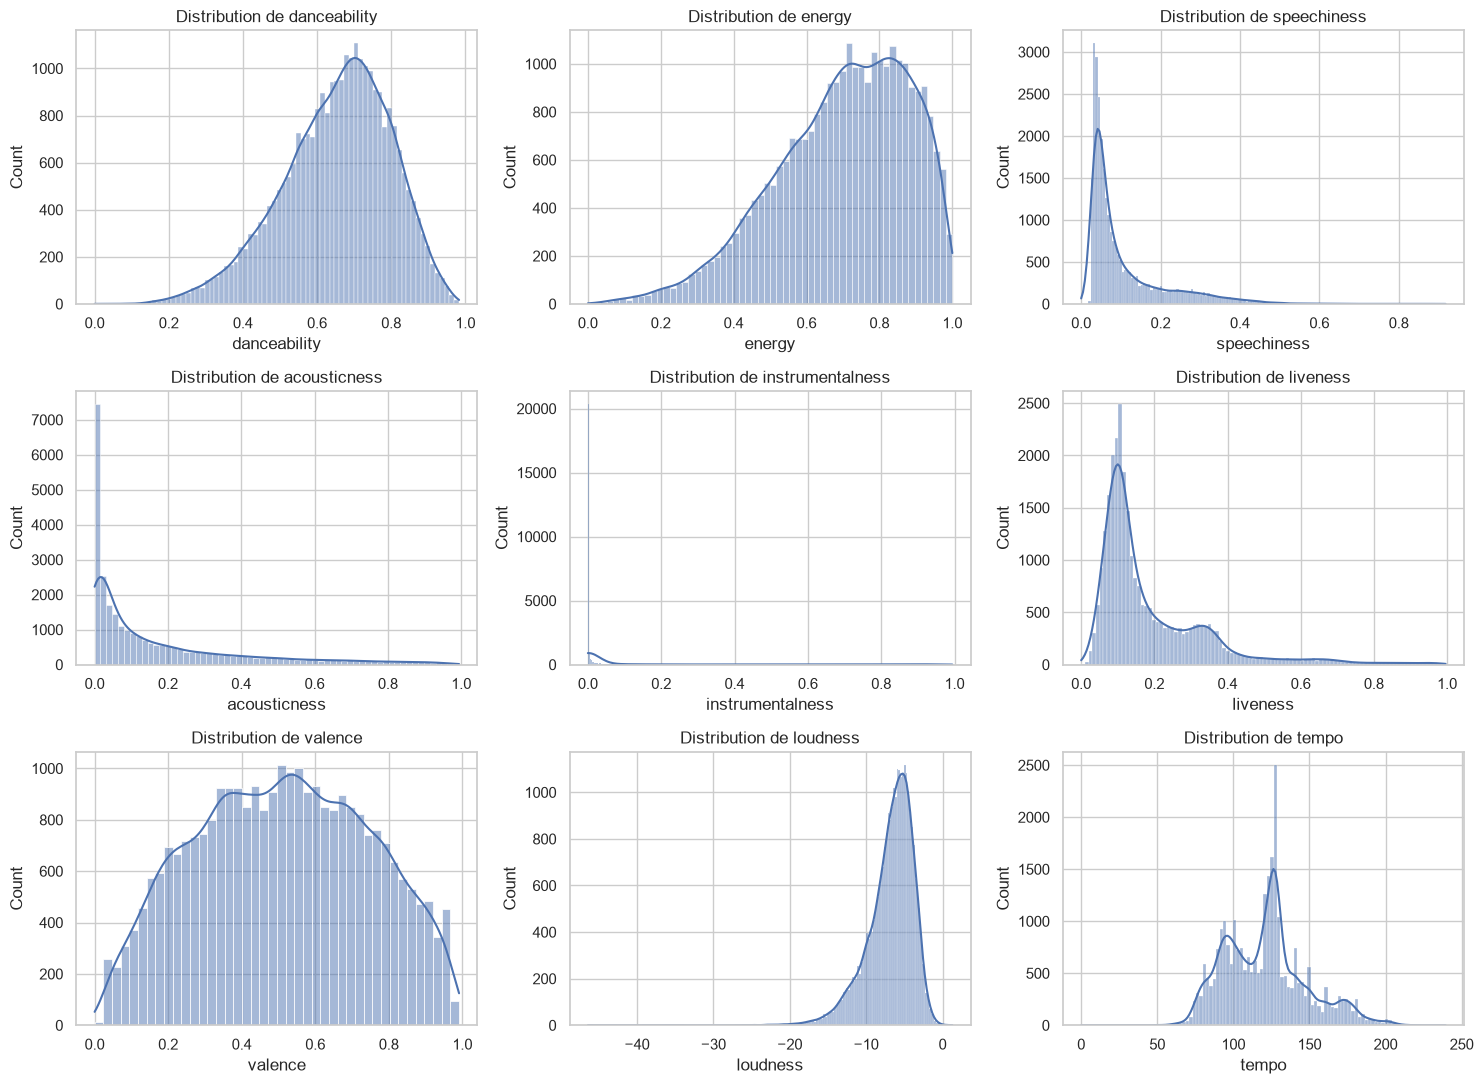

In [65]:

audio_cols = ['danceability', 'energy', 'speechiness', 'acousticness',
              'instrumentalness', 'liveness', 'valence', 'loudness', 'tempo']
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for col, ax in zip(audio_cols, axes.flat):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution de {col}')
plt.tight_layout()
plt.show()

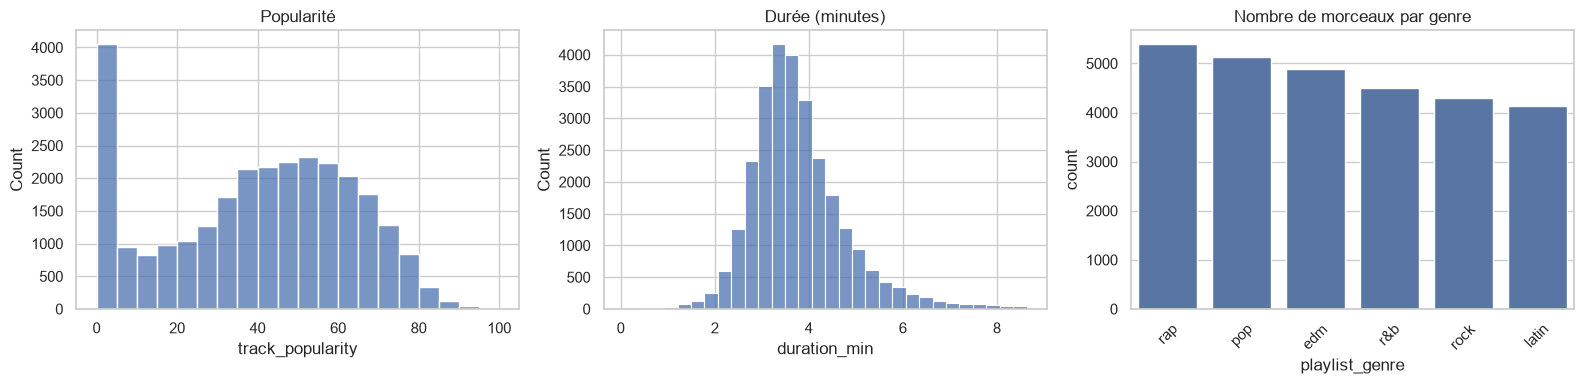

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x='track_popularity', bins=20, ax=axes[0])
axes[0].set_title('Popularité')
sns.histplot(data=df, x='duration_min', bins=30, ax=axes[1])
axes[1].set_title('Durée (minutes)')
sns.countplot(data=df, x='playlist_genre', order=df['playlist_genre'].value_counts().index, ax=axes[2])
axes[2].tick_params(axis='x', rotation=45)
axes[2].set_title('Nombre de morceaux par genre')
plt.tight_layout()
plt.show()

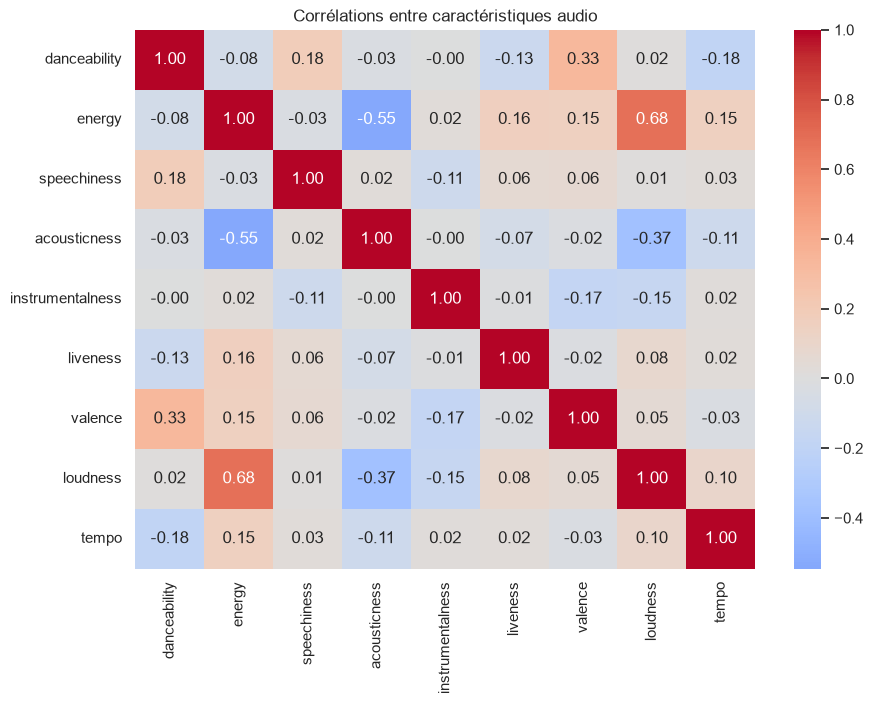

Corrélations avec energy :


,correlation
loudness,0.682138
acousticness,-0.545886
liveness,0.163709
tempo,0.151545
valence,0.149710
danceability,-0.081436
speechiness,-0.029008
instrumentalness,0.023818


In [67]:
corr = df[audio_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Corrélations entre caractéristiques audio')
plt.show()
print('Corrélations avec energy :')
display(corr['energy'].drop('energy').sort_values(key=abs, ascending=False).to_frame('correlation'))


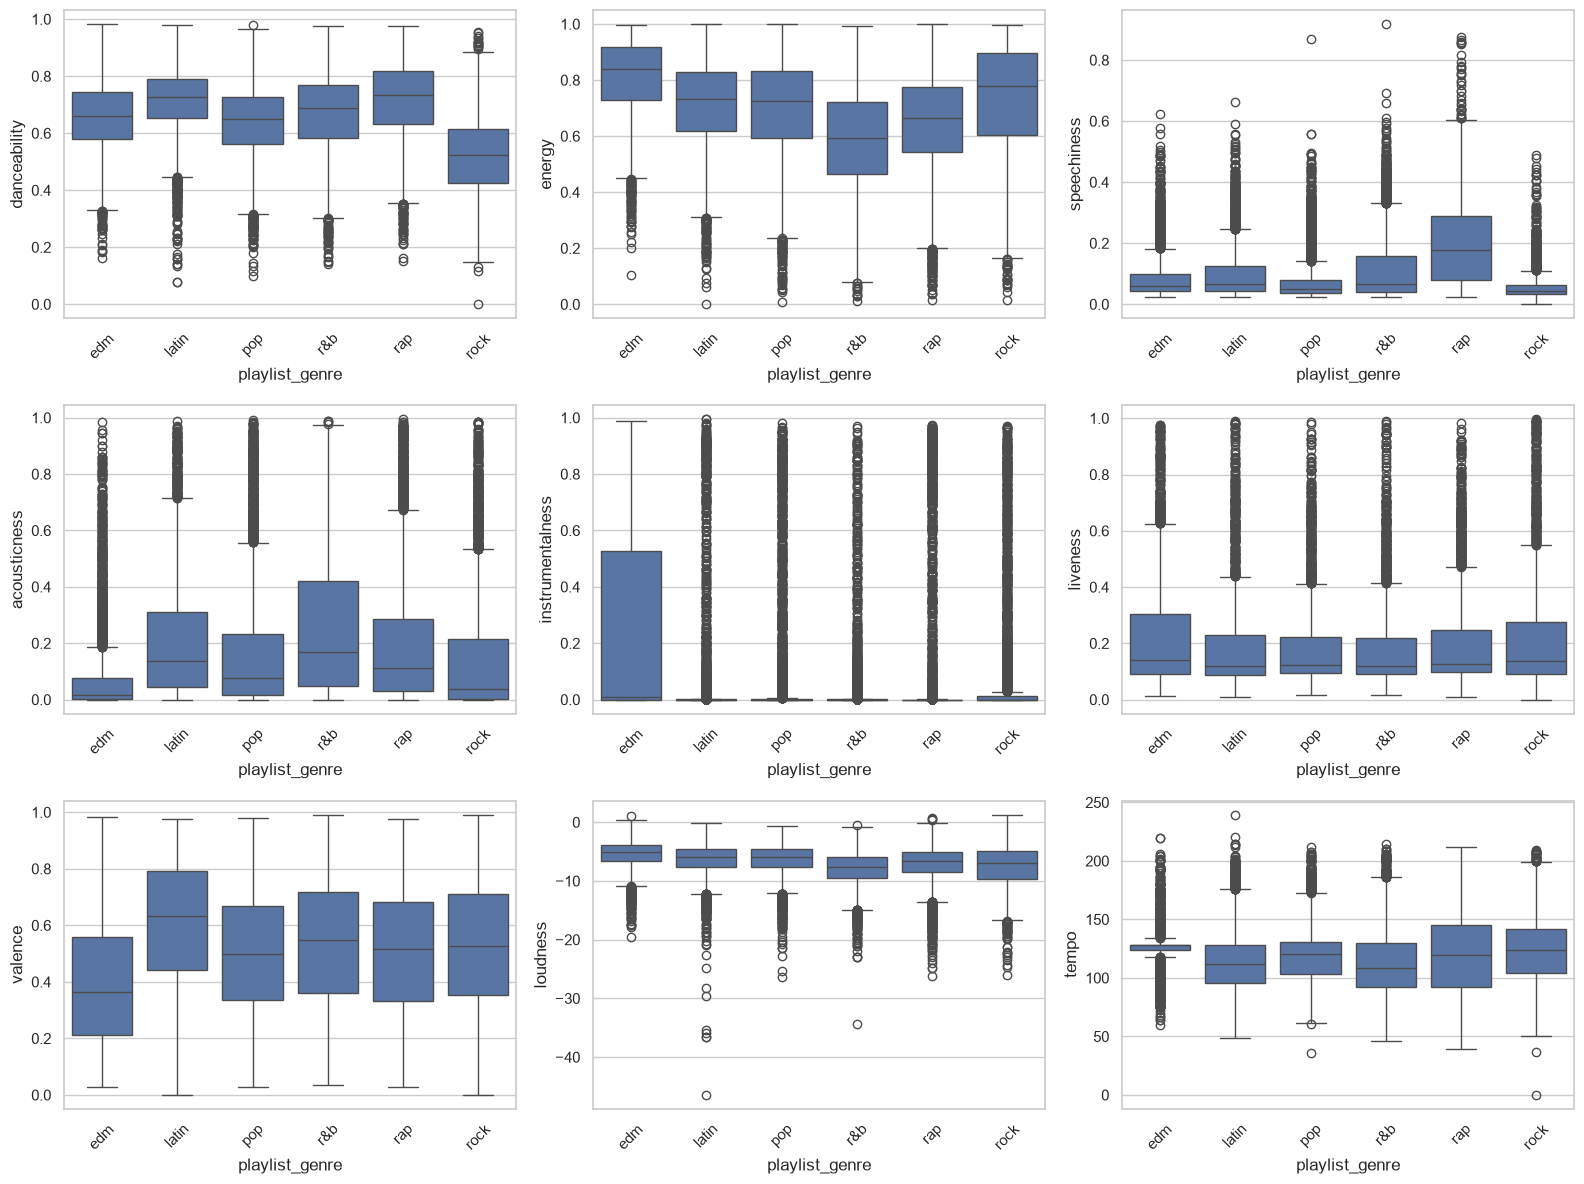

In [68]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for col, ax in zip(audio_cols, axes.flat):
    sns.boxplot(data=df, x='playlist_genre', y=col, ax=ax)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


,popularite_moyenne
playlist_genre,
pop,45.905300
rap,41.822811
latin,41.439691
rock,39.694309
r&b,35.929396
edm,30.678286


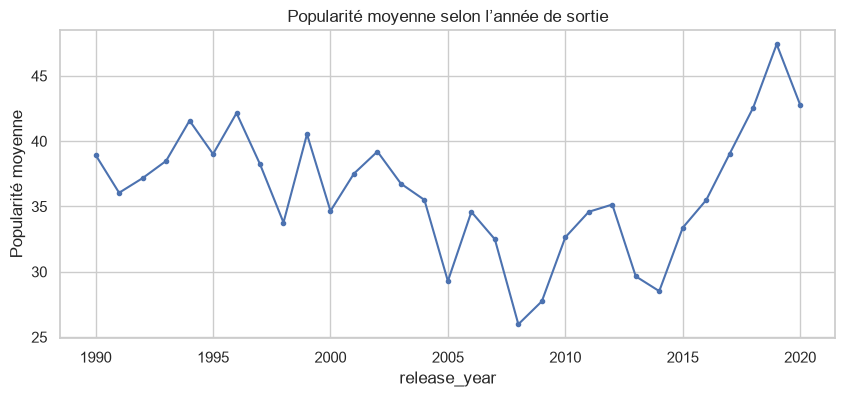

In [69]:
display(df.groupby('playlist_genre', observed=True)['track_popularity'].mean().sort_values(ascending=False).to_frame('popularite_moyenne'))
df['release_year'] = pd.to_datetime(df['track_album_release_date'], errors='coerce').dt.year
popularite_annee = df.dropna(subset=['release_year']).groupby('release_year', observed=True)['track_popularity'].mean()
popularite_annee = popularite_annee.loc[(popularite_annee.index >= 1990) & (popularite_annee.index <= 2020)]
popularite_annee.plot(figsize=(10, 4), marker='.')
plt.title('Popularité moyenne selon l’année de sortie')
plt.ylabel('Popularité moyenne')
plt.show()

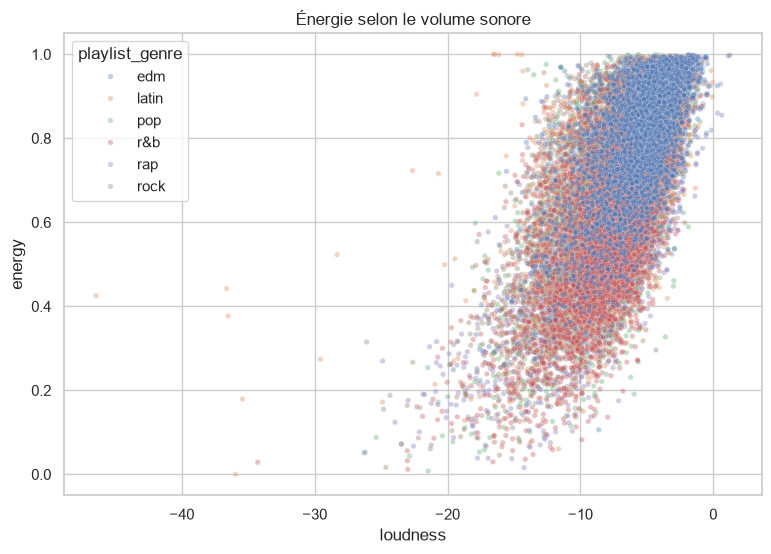

In [70]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='loudness', y='energy', hue='playlist_genre', alpha=0.35, s=15)
plt.title('Énergie selon le volume sonore')
plt.show()

In [71]:

print('Top 10 artistes :')
display(df['track_artist'].value_counts().head(10).to_frame('nombre_morceaux'))
print('Top 10 morceaux les plus populaires :')
display(df.nlargest(10, 'track_popularity')[['track_name', 'track_artist', 'track_popularity', 'playlist_genre']])

Top 10 artistes :


,nombre_morceaux
track_artist,
Queen,130
Martin Garrix,87
Don Omar,84
David Guetta,81
Dimitri Vegas & Like Mike,68
Hardwell,68
Drake,68
The Chainsmokers,66
Logic,65


Top 10 morceaux les plus populaires :


,track_name,track_artist,track_popularity,playlist_genre
1551,Dance Monkey,Tones and I,100,pop
20092,ROXANNE,Arizona Zervas,99,latin
687,Tusa,KAROL G,98,pop
711,Memories,Maroon 5,98,pop
716,Blinding Lights,The Weeknd,98,pop
1301,Circles,Post Malone,98,pop
5508,The Box,Roddy Ricch,98,rap
689,everything i wanted,Billie Eilish,97,pop
1302,Don't Start Now,Dua Lipa,97,pop
3155,Falling,Trevor Daniel,97,pop


Regression

In [72]:
from sklearn.base import clone

reg_num_cols = ['danceability', 'speechiness', 'acousticness', 'instrumentalness',
                'liveness', 'valence', 'loudness', 'tempo', 'duration_min', 'key', 'mode']
reg_cat_cols = ['playlist_genre', 'playlist_subgenre']
reg_data = df.dropna(subset=reg_num_cols + ['energy']).copy()
reg_indices_train, reg_indices_test = train_test_split(
    reg_data.index, test_size=0.2, random_state=42
)
y_reg_train = reg_data.loc[reg_indices_train, 'energy']
y_reg_test = reg_data.loc[reg_indices_test, 'energy']

corr_train = reg_data.loc[reg_indices_train, reg_num_cols + ['energy']].corr(numeric_only=True)['energy'].drop('energy')
simple_feature = corr_train.abs().idxmax()
print('Variable la plus corrélée avec energy (train) :', simple_feature, corr_train[simple_feature])

Variable la plus corrélée avec energy (train) : loudness 0.6819897217185334


In [73]:
X_simple_train = reg_data.loc[reg_indices_train, [simple_feature]]
X_simple_test = reg_data.loc[reg_indices_test, [simple_feature]]
X_num_train = reg_data.loc[reg_indices_train, reg_num_cols]
X_num_test = reg_data.loc[reg_indices_test, reg_num_cols]
X_cat_train = pd.get_dummies(reg_data.loc[reg_indices_train, reg_num_cols + reg_cat_cols], columns=reg_cat_cols, drop_first=True, dtype=int)
X_cat_test = pd.get_dummies(reg_data.loc[reg_indices_test, reg_num_cols + reg_cat_cols], columns=reg_cat_cols, drop_first=True, dtype=int).reindex(columns=X_cat_train.columns, fill_value=0)

In [74]:
def evaluer_regression(nom, estimateur, Xtr, Xte, ytr, yte):
    estimateur.fit(Xtr, ytr)
    pred_train = estimateur.predict(Xtr)
    pred_test = estimateur.predict(Xte)
    return {
        'modele': nom,
        'R2_train': r2_score(ytr, pred_train),
        'R2_test': r2_score(yte, pred_test),
        'MAE_train': mean_absolute_error(ytr, pred_train),
        'MAE_test': mean_absolute_error(yte, pred_test),
        'RMSE_train': np.sqrt(mean_squared_error(ytr, pred_train)),
        'RMSE_test': np.sqrt(mean_squared_error(yte, pred_test)),
        'estimateur': estimateur,
        'pred_test': pred_test,
    }

In [75]:
# =========================================================
# Nouveau modèle simplifié (Top 4 indices)
# =========================================================
top4_cols = ['loudness', 'acousticness', 'valence', 'danceability']

X_top4_train = reg_data.loc[reg_indices_train, top4_cols]
X_top4_test = reg_data.loc[reg_indices_test, top4_cols]

# Évaluation du modèle avec seulement 4 variables
resultat_top4 = evaluer_regression(
    'Linéaire (Top 4 indices)', 
    LinearRegression(), 
    X_top4_train, 
    X_top4_test, 
    y_reg_train, 
    y_reg_test
)

In [76]:
reg_results = []
reg_results.append(evaluer_regression('Linéaire simple', LinearRegression(), X_simple_train, X_simple_test, y_reg_train, y_reg_test))
reg_results.append(evaluer_regression('Linéaire numérique', LinearRegression(), X_num_train, X_num_test, y_reg_train, y_reg_test))
reg_results.append(evaluer_regression('Linéaire + catégories', LinearRegression(), X_cat_train, X_cat_test, y_reg_train, y_reg_test))
reg_results.append(evaluer_regression('Forêt aléatoire', RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1), X_num_train, X_num_test, y_reg_train, y_reg_test))
reg_results.append(resultat_top4)

regression_comparaison = pd.DataFrame([{k: v for k, v in r.items() if k not in ['estimateur', 'pred_test']} for r in reg_results])
display(regression_comparaison.sort_values('R2_test', ascending=False))



,modele,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test
3,Forêt aléatoire,0.944910,0.719950,0.031677,0.074881,0.043009,0.097646
2,Linéaire + catégories,0.660232,0.670992,0.083548,0.083383,0.106812,0.105837
1,Linéaire numérique,0.624948,0.636290,0.088238,0.088460,0.112221,0.111279
4,Linéaire (Top 4 indices),0.596792,0.610047,0.091978,0.092140,0.116357,0.115224
0,Linéaire simple,0.465110,0.466055,0.106431,0.107613,0.134017,0.134829


In [77]:
meilleur_reg = max(reg_results, key=lambda resultat: resultat['R2_test'])
meilleur_reg_lineaire = max(reg_results[:3], key=lambda resultat: resultat['R2_test'])
print('Coefficients du meilleur modèle linéaire (triés par valeur absolue) :')
colonnes_coef = X_cat_train.columns if meilleur_reg_lineaire['modele'] == 'Linéaire + catégories' else X_num_train.columns if meilleur_reg_lineaire['modele'] == 'Linéaire numérique' else X_simple_train.columns
coefs = pd.Series(meilleur_reg_lineaire['estimateur'].coef_, index=colonnes_coef)
display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).to_frame('coefficient'))
print('Coefficient de loudness :', coefs.get('loudness', 'non utilisé'))


Coefficients du meilleur modèle linéaire (triés par valeur absolue) :


,coefficient
acousticness,-0.223109
danceability,-0.158702
valence,0.155439
liveness,0.082216
instrumentalness,0.078806
speechiness,0.065114
playlist_subgenre_big room,0.054995
playlist_genre_r&b,-0.050354
playlist_subgenre_hard rock,0.049882
playlist_subgenre_neo soul,-0.042349


Coefficient de loudness : 0.03244984549588452


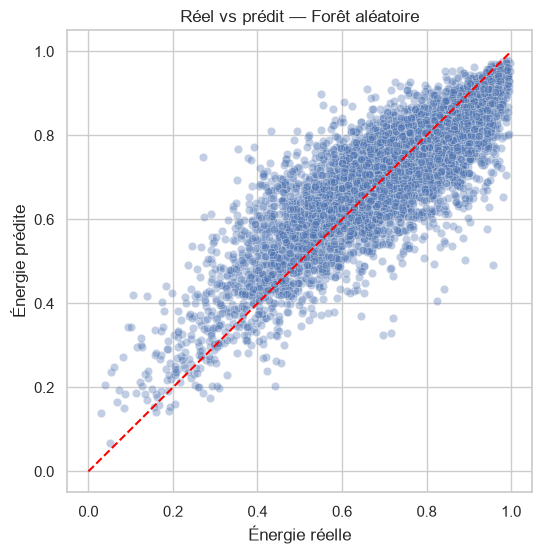

In [78]:
plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_reg_test, y=meilleur_reg['pred_test'], alpha=0.35)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('Énergie réelle')
plt.ylabel('Énergie prédite')
plt.title(f"Réel vs prédit — {meilleur_reg['modele']}")
plt.show()

In [79]:
# Bonus : prédire la popularité avec les mêmes caractéristiques numériques.
pop_data = df.dropna(subset=reg_num_cols + ['track_popularity'])
pop_train_idx, pop_test_idx = train_test_split(pop_data.index, test_size=0.2, random_state=42)
pop_result = evaluer_regression(
    'Popularité - forêt',
    RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1),
    pop_data.loc[pop_train_idx, reg_num_cols], pop_data.loc[pop_test_idx, reg_num_cols],
    pop_data.loc[pop_train_idx, 'track_popularity'], pop_data.loc[pop_test_idx, 'track_popularity']
)
display(pd.DataFrame([{k: v for k, v in pop_result.items() if k not in ['estimateur', 'pred_test']}]))

,modele,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test
0,Popularité - forêt,0.805316,0.028858,8.335797,19.220533,10.452988,23.402323


Enregistrer les modèles

In [80]:
import joblib

# 1. Modèle prédictif final (Forêt Aléatoire qui a le meilleur R2 test)
joblib.dump(meilleur_reg['estimateur'], 'modele_regression_energie.joblib')

# 2. Meilleur modèle linéaire (pour afficher les coefficients ou l'utiliser en prédiction explicable)
joblib.dump(meilleur_reg_lineaire['estimateur'], 'modele_lineaire_energie.joblib')

# 3. Liste des colonnes nécessaires pour les prédictions
joblib.dump(X_num_train.columns.tolist(), 'colonnes_numeriques.joblib')
joblib.dump(X_cat_train.columns.tolist(), 'colonnes_categories.joblib')

print("Modèles et colonnes exportés avec succès !")

Modèles et colonnes exportés avec succès !
